# Week 3 · Records and data

One offer is easy. A real day has many. This week you keep one record per offer, add them up, and find any offer by its ID.

| | |
|---|---|
| **This week's question** | How does a system remember many things and tell them apart? |
| **Python you will learn** | lists, dictionaries, a list of dictionaries, `for` loops, the accumulator pattern, finding by ID |
| **Principle 3** | **One record per real thing.** Each thing gets one record and one unique ID. Do not store the same fact twice. |
| **Part you build** | `total_portions` and `find_offer` (⭐⭐ `portions_by_category`) |

*Campus FoodBridge is fictional. All organisations, people and numbers are invented.*

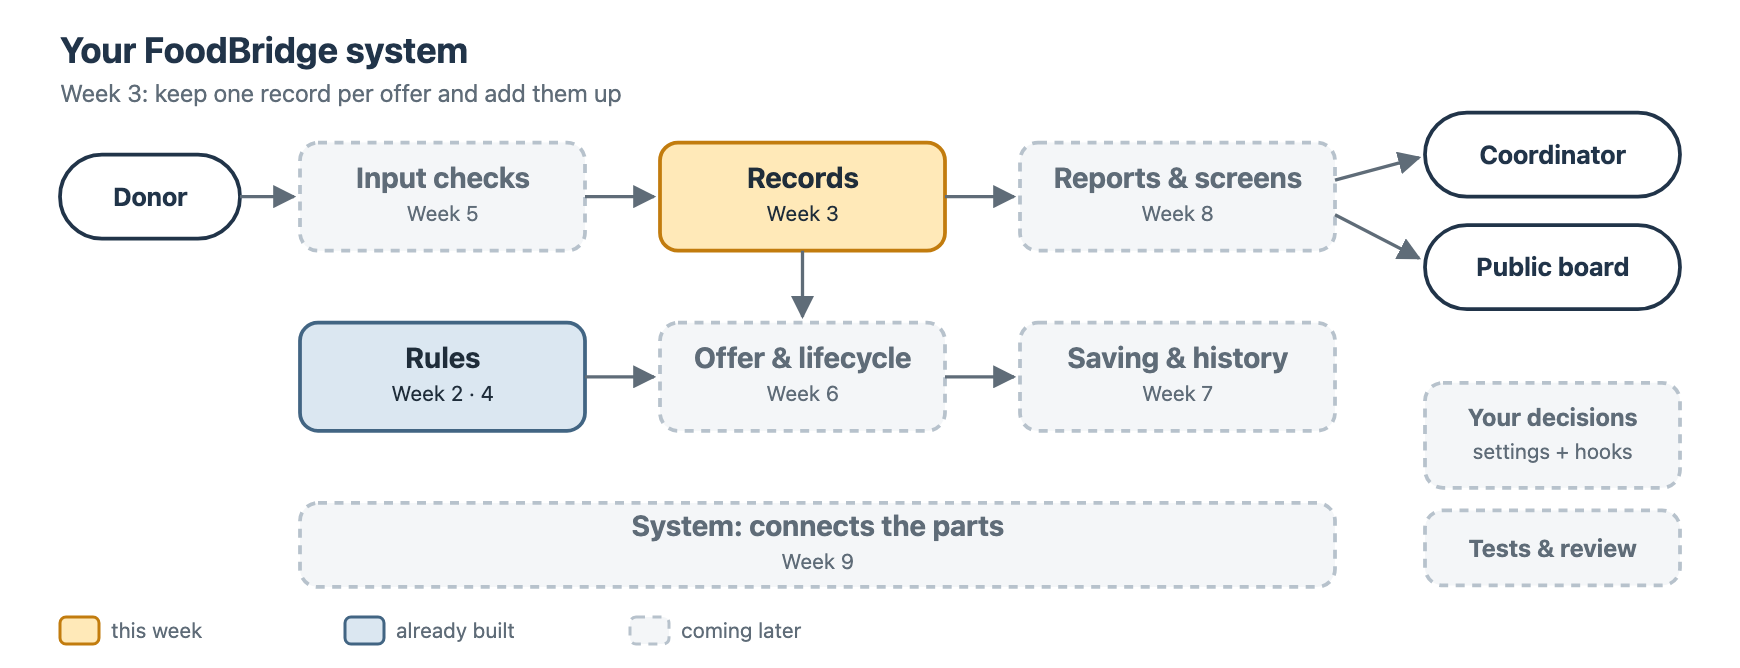

### The story so far

Last week you wrote the rules: when a pickup needs a **team**, and which offers are **urgent**. The rules work. This morning, the phone tests them.

It is 7:30. Sunrise Bakery calls with 30 portions of bread rolls. Before the coordinator has finished writing, the Campus Canteen calls, then Green Market Stall, then Lotus Cafe. Four offers — and the paper notebook is already full: names in one column, numbers in another, and one number written twice.

Rules are not enough. A system also has to **remember**: every offer kept apart, nothing lost, nothing counted twice. That is this week's work.

### Warm-up · The boundary from Week 2

Last week you turned the coordinator's words into a rule: **20 portions or more need a team.** The interesting case was the boundary itself — exactly 20.

🤔 **Predict:** after you fix the function below, what do the three `print` lines give? Say your answers out loud before you run the cell.

Complete the function so it follows the Week 2 rule.

In [ ]:
def needs_team(portions):
    # TODO 1: Week 2's rule — a team at 20 portions or more.
    # TODO 2: Change `return False` so the function follows the rule.
    return False

print(needs_team(19))
print(needs_team(20))
print(needs_team(21))

<details><summary>Show a possible answer</summary>

```python
def needs_team(portions):
    return portions >= 20
```

Expected: `False`, then `True`, then `True`, one per line. The trap is 20 itself: the rule says "20 or more", so the comparison is `>=`, not `>`.

</details>

## Before you start

1. Click **Copy to Drive** (or **File → Save a copy in Drive**), then work in your copy.
2. Run the setup cell. Run it again after a runtime restart.
3. ⭐ = core for everyone, ⭐⭐ = optional stretch.

In [ ]:
# @title ▶ Run this cell first (setup) — it prepares the FoodBridge system
# It unpacks the course system that is stored inside this notebook.
# No internet, no installation. Run it again after Colab restarts.
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.3"
_KIT_SHA = "689b26d4950abba56ebe2affd1b5fc02e3165a03f712d0b3be8ba9c1432cea43"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("This notebook's course files are damaged. Download a fresh copy.")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
print("✅ FoodBridge system ready (version " + bridge.KIT_VERSION + "). You can continue.")


## Class warm-up · Research 2 exchange (10 min)

In groups of three, share the rule you researched.

1. Read your rule aloud, exactly as a program would need it. Can your group find a case it does not cover?
2. Share your **boundary** case. Does everyone agree what should happen exactly at the limit?
3. Share your **odd** case (missing, negative or unusual input). What should the system do, and who decides?

📝 **One edge case from a classmate that I want to remember:**

## Session 1 · Learn: many records (30 min)

### The idea: records, IDs and the data model

Think of a class list. Each student is **one row**. Every row has the same columns: student ID, name, class. Two students can have the same name, but never the same student ID. When the office needs your marks, it looks you up by ID, not by name.

Our system works the same way. Each offer is one **record**: one group of facts about one real offer. Every record has the same **fields**, and one unique **ID** such as `"F001"`. The list of fields is the **data model**. Choosing it is a design decision: which facts do we keep, and which do we leave out?

| Field | Example | Why we keep it |
|---|---|---|
| `id` | `"F001"` | to tell offers apart, even when two have the same food |
| `donor`, `contact` | `"Sunrise Bakery"`, `"sunrise@example.org"` | who to thank and call back (the contact is private) |
| `food`, `category` | `"Bread rolls"`, `"bread"` | what it is; the category decides if we accept it |
| `portions`, `hours_left` | `30`, `5` | how much, and how soon it must be collected |
| `status`, `partner` | `"approved"`, `"Hope Children's Centre"` | where it is in the process, and who receives it |

Two design choices hide in this table:

- **Why an ID, not the food name?** Two bakeries can both offer "Bread rolls". A donor can fix a spelling mistake in the food name. An ID is never shared and never changes.
- **What is missing on purpose?** There is no "total portions today" field. A total is **calculated** from the records when you need it. If you stored it too, you would have the same fact twice, and one day the two copies would disagree.

One record on paper is easy to lose, and four records are easy to mix up. First we need a way to keep many values together, in order.

### 1 · A list keeps many values in order

- Square brackets `[ ]` make a list. Items are separated by commas.
- `volunteers[0]` is the **first** item. The position number is called the **index**.
- `len(...)` counts the items. `.append(...)` adds one at the end. `in` gives `True` or `False`.

🤔 **Predict** each line before you run the cell. What will `volunteers[3]` be after the `append`?

In [ ]:
volunteers = ["Dara", "Sophea", "Vanna"]
print(volunteers[0])          # positions start at 0
print(len(volunteers))        # how many items
volunteers.append("Kosal")    # add one at the end
print(volunteers)
print(volunteers[3])
print("Sophea" in volunteers) # is it in the list?
# print(volunteers[4])        # remove the # to see the error, then put it back

**Prediction:** …  **Result:** …

`volunteers[4]` stops with `IndexError: list index out of range`: there is no fifth item. Read the last line of an error first.

### 2 · A dictionary gives each value a name

A **dictionary** stores pairs: a **key** (the name) and a **value**. You look up a value by its key, not by a position.

In [ ]:
item = {"name": "Notebook", "price_riel": 4000, "in_stock": 25}
print(item["price_riel"])
item["price_riel"] = 3500        # change a value
item["colour"] = "blue"          # add a new key
print(item)
print(list(item.keys()))
print(list(item.values()))
print(item.get("size"))
print(item.get("size", "one size"))

- Curly brackets `{ }` make a dictionary. Each pair is written `key: value`.
- Keys are exact, like text comparison in Week 2: `"Price_riel"` is a different key.

What if the key is missing? `item["size"]` stops with a `KeyError`. `.get(...)` is the polite way to ask: it gives `None` (or a default you choose) instead of an error.

🤔 **Predict:** what do the two lines at the end of the cell above print?

**Prediction:** …  **Result:** …

### 3 · A record is a dictionary, and a day is a list of records

One offer is one dictionary. Many offers are a **list of dictionaries**. This is the shape almost every information system uses, from a class list to a bank statement.

In [ ]:
offers = [
    {"id": "F001", "food": "Bread rolls", "portions": 30, "hours_left": 5},
    {"id": "F002", "food": "Fried rice boxes", "portions": 18, "hours_left": 2},
]
print(len(offers))
print(offers[1])
print(offers[1]["food"])

🤔 `offers[1]["food"]` has two steps. Say them in words: first …, then … .

**My answer:** …

A list of records holds the whole day, and we can read any field in it. The next problem: doing the same thing to every record, without writing it out again and again.

### 4 · `for`: do the same thing for every item

A **loop** repeats the indented lines once for each item in a list. The name after `for` points to the current item.

The second loop is the same idea with records. A good habit: a **plural** name for the list (`offers`) and a **singular** name for one item (`offer`).

In [ ]:
prices_riel = [4000, 1500, 2000]
for price_riel in prices_riel:
    print("Price:", price_riel, "riel")
print("Done")

for offer in offers:
    print(offer["id"], "·", offer["food"], "·", offer["portions"], "portions")

A loop can visit every record. But the coordinator does not need a visit — she needs one number for the whole day. So we keep a running total while the loop runs.

### 5 · The accumulator: start at zero, add each item

To add up a list, keep a running total. This pattern is called an **accumulator**.

In [ ]:
prices_riel = [4000, 1500, 2000]
total_riel = 0                    # 1. start before the loop
for price_riel in prices_riel:
    total_riel += price_riel      # 2. add each item
print(total_riel)                 # 3. use the result after the loop

- `total_riel += price_riel` means `total_riel = total_riel + price_riel`.
- The same pattern **counts**: start `count = 0`, then `count += 1` for each item you want to count.

🤔 **Predict:** what would print if `total_riel = 0` were moved **inside** the loop (indented, just above the `+=` line)? Try it, then move it back.

**Prediction:** …  **Result:** …  **Why:** …

Adding up looks at all the records together. Finding does the opposite: it looks for one record, and stops the moment it is found.

### 6 · Find one record by its ID

To find a record, look at each one in turn. When the ID matches, **return** it: `return` stops the loop at once. Only **after** the loop has checked every record do you know it is not there; then return `None`.

In [ ]:
shop_items = [
    {"code": "N01", "name": "Notebook", "price_riel": 4000},
    {"code": "P02", "name": "Pen", "price_riel": 1500},
    {"code": "R03", "name": "Ruler", "price_riel": 2000},
]

def find_item(items, wanted_code):
    for item in items:
        if item["code"] == wanted_code:
            return item          # found: stop and send it back
    return None                  # checked every item: not found

print(find_item(shop_items, "P02"))
print(find_item(shop_items, "X99"))

Look at the indentation of `return None`. It lines up with `for`, not with `if`. It runs only when the loop has finished without finding anything.

🤔 **Predict:** what does `find_item(shop_items, "p02")` return? Why?

**My answer:** …

### Worked example · Bread portions only

Before you build, watch the pattern once, on a smaller question. The coordinator asks: *"How many portions of bread do we have this morning?"*

We answer in four steps:

1. Start a total at 0.
2. Loop over the records.
3. Add the portions **only** when the record's category is `"bread"`.
4. Return the total after the loop.

It is the accumulator from §5, with one `if` inside it. Here are the three morning offers:

In [ ]:
morning_offers = [
    {"id": "M01", "food": "Bread rolls", "category": "bread", "portions": 30},
    {"id": "M02", "food": "Bananas", "category": "fruit", "portions": 40},
    {"id": "M03", "food": "Baguettes", "category": "bread", "portions": 12},
]

def bread_portions(records):
    total = 0
    for record in records:
        if record["category"] == "bread":
            total += record["portions"]
    return total

print(bread_portions(morning_offers))

**How it works:** the loop visits all three records, but the `if` lets only two of them reach the `+=` line: 30 + 12 = 42. The bananas record is visited, checked, and skipped.

In Session 3, Part 1, you write the same pattern with no `if` at all: for `total_portions`, every record counts.

## Session 2 · Practise and judge (60 min)

You now have the four tools: list, dictionary, loop, accumulator. This session gives you a fresh evening of offers. Use the tools — and judge other people's code, not only your own.

Run this cell first. It creates four evening offers that P2, P3 and S1 use.

In [ ]:
evening_offers = [
    {"id": "F101", "food": "Steamed buns", "category": "bread", "portions": 24, "hours_left": 2},
    {"id": "F102", "food": "Pineapple", "category": "fruit", "portions": 15, "hours_left": 10},
    {"id": "F103", "food": "Chicken rice", "category": "rice meals", "portions": 35, "hours_left": 3},
    {"id": "F104", "food": "Baguettes", "category": "bread", "portions": 8, "hours_left": 30},
]
print(len(evening_offers), "evening offers ready")

### ⭐ P1 · Predict the lookups

Write your prediction for each line, then run.

In [ ]:
foods = ["Bread rolls", "Fried rice boxes", "Bananas"]
offer = {"id": "F003", "food": "Bananas", "portions": 40}
print(foods[1])
print(len(foods))
print(offer["portions"] + 10)
print("Mangoes" in foods)
print(offer.get("partner"))
print(offer.get("partner", "none yet"))

**Predictions:** …  **Results:** …

<details><summary>Show a possible answer</summary>

`Fried rice boxes`, `3`, `50`, `False`, `None`, `none yet`. The index `1` is the **second** item, because positions start at 0. The offer has no `"partner"` key, so `.get` gives `None` or the default you chose.

</details>

### ⭐ P2 · How much is urgent?

The coordinator asks: *"How many evening offers are urgent (3 hours or less), and how many portions is that?"* Use two accumulators: one counts, one adds.

The starter loop contains `pass`. It means "do nothing": it only keeps an empty loop valid. Delete it when you write your code.

In [ ]:
URGENT_HOURS = 3

urgent_count = 0
urgent_portions = 0
for offer in evening_offers:
    # TODO: if this offer's hours_left is at most URGENT_HOURS,
    #       add 1 to urgent_count and add its portions to urgent_portions
    pass

print(urgent_count, "urgent offers,", urgent_portions, "portions")

<details><summary>Show a possible answer</summary>

```python
for offer in evening_offers:
    if offer["hours_left"] <= URGENT_HOURS:
        urgent_count += 1
        urgent_portions += offer["portions"]
```

Expected: `2 urgent offers, 59 portions` (F101 with 2 hours and F103 with exactly 3 hours). Did you remember the boundary from Week 2? `<=` includes F103.

</details>

### ⭐ P3 · Repair the search

An AI assistant wrote this search. It finds F101, but it says F103 does not exist. Run it, find the bug, and fix it.

In [ ]:
def find_by_id(records, offer_id):
    for record in records:
        if record["id"] == offer_id:
            return record
        else:
            return None

print(find_by_id(evening_offers, "F101"))
print(find_by_id(evening_offers, "F103"))   # should find Chicken rice
print(find_by_id(evening_offers, "F999"))   # should be None

**Why it fails for F103:** …

<details><summary>Show a possible answer</summary>

The first record is F101. For any other ID, the `else` branch runs on that **first** record and returns `None`, so the loop never reaches F103. Remove the `else` and put `return None` **after** the loop, lined up with `for`. A search can only say "not found" after it has looked at everything.

</details>

### ⭐ P4 · Write one record

A donor phones the coordinator: *"This is Riverside Restaurant. We have 25 portions of noodle soup. It must be collected within 3 hours. Email riverside@example.org."*

Write this offer as **one record**, with the same nine fields as the data model table in Session 1. The last offer today is F004, so give it the next ID. A new offer has status `"new"` and no partner yet (`""`).

Run the next cell after your record: it checks your record against the data model.

In [ ]:
new_offer = {}   # TODO: id, donor, contact, food, category, portions, hours_left, status, partner
print(new_offer)

In [ ]:
model_fields = ["id", "donor", "contact", "food", "category", "portions", "hours_left", "status", "partner"]
for field in model_fields:
    print("✅" if field in new_offer else "❌", field)
print("✅" if type(new_offer.get("portions")) == int else "❌", "portions is a whole number, not text")

🤔 Two questions about your record:

1. Which field must **never** appear on the public board?
2. Should you add a field `"total_portions_today": 125` to this record? Why not?

**My answers:** …

<details><summary>Show a possible answer</summary>

```python
new_offer = {"id": "F005", "donor": "Riverside Restaurant", "contact": "riverside@example.org",
             "food": "Noodle soup", "category": "soup", "portions": 25, "hours_left": 3,
             "status": "new", "partner": ""}
```

1. `contact` is private: only the coordinator needs it.
2. A day total is not a fact about **this** offer. It changes every time another offer arrives or is rejected, and this copy would not change with it. Calculate totals from the records instead.

Remember this soup: in Session 3 you will see why the system refuses it today.

</details>

### ⭐⭐ S1 · A dictionary that counts

How many evening offers are there **per category**? Use a dictionary as the accumulator: one key per category, and the value is the count so far. `counts.get(category, 0)` gives `0` the first time you meet a category.

In [ ]:
count_by_category = {}
for offer in evening_offers:
    # TODO: add 1 to the count for this offer's category
    pass
print(count_by_category)

<details><summary>Show a possible answer</summary>

```python
for offer in evening_offers:
    category = offer["category"]
    count_by_category[category] = count_by_category.get(category, 0) + 1
```

Expected: `{'bread': 2, 'fruit': 1, 'rice meals': 1}`.

</details>

### ⭐ P5 · The urgent list

The coordinator is leaving now. She needs the **food names** of the urgent evening offers (3 hours or less), one per line, so she can phone the partners in order.

📖 If `for` loops still feel shaky, do the micro-exercise in [**Python Basics §06 · Loops and adding things up**](Python_Basics.ipynb#id-06-loops-and-adding-things-up) first.

In [ ]:
for offer in evening_offers:
    # TODO: if this offer's hours_left is at most 3, print its food
    pass

<details><summary>Show a possible answer</summary>

```python
for offer in evening_offers:
    if offer["hours_left"] <= 3:
        print(offer["food"])
```

Expected: `Steamed buns` then `Chicken rice`, one per line. F102 has 10 hours and F104 has 30, so they are not printed.

</details>

### ⭐⭐ P6 · Portions in one category

Write `category_portions(records, category)`. It returns the total portions of the records in that category, and `0` when no record matches. It is the worked example from Session 1, made general: the category is now a parameter. Test it on the evening offers: bread, then fruit, then soup.

📖 If writing a function that returns a value is still new, do the micro-exercise in [**Python Basics §07 · Functions and `return`**](Python_Basics.ipynb#id-07-functions-and-return) first.

In [ ]:
def category_portions(records, category):
    # TODO 1: start a total at 0
    # TODO 2: loop over the records; add the portions when the record's category matches
    # TODO 3: return the total
    return None

print(category_portions(evening_offers, "bread"))
print(category_portions(evening_offers, "fruit"))
print(category_portions(evening_offers, "soup"))

<details><summary>Show a possible answer</summary>

```python
def category_portions(records, category):
    total = 0
    for record in records:
        if record["category"] == category:
            total += record["portions"]
    return total
```

Expected: `32`, `15`, `0`. No evening offer has category `"soup"`, so the loop adds nothing and the function returns the starting total.

</details>

### ⭐⭐⭐ P7 · Describe one offer

Write `describe_offer(records, offer_id)`. It finds the record (remember P3: the "not found" answer comes only **after** the loop) and returns one line of text:

- found: `"F103: Chicken rice, 35 portions, 3 hours left"`
- not found: `"F999: not found"`

Use an f-string to build the line (Python Basics §03 · Text and f-strings).

📖 If reading a value out of a record still feels slow, do the micro-exercise in [**Python Basics §05 · Lists, dictionaries, tuples, sets**](Python_Basics.ipynb#id-05-lists-dictionaries-tuples-sets) first.

In [ ]:
def describe_offer(records, offer_id):
    # TODO 1: loop over the records
    # TODO 2: if this record's "id" equals offer_id, return the description line
    # TODO 3: after the loop, return offer_id + ": not found"
    return "?"

print(describe_offer(evening_offers, "F103"))
print(describe_offer(evening_offers, "F999"))

<details><summary>Show a possible answer</summary>

```python
def describe_offer(records, offer_id):
    for record in records:
        if record["id"] == offer_id:
            return f"{record['id']}: {record['food']}, {record['portions']} portions, {record['hours_left']} hours left"
    return f"{offer_id}: not found"
```

Expected: `F103: Chicken rice, 35 portions, 3 hours left` and `F999: not found`. Inside an f-string, use single quotes for the keys: `record['id']`.

</details>

### ⚖️ Good or risky?

You asked an AI assistant to *"store today's offers and keep a running total."* It gave you **Version A** (first cell). A classmate wrote **Version B** (second cell). Run both. They print the same total.

In [ ]:
offers_by_food = {
    "Bread rolls": {"donor": "Sunrise Bakery", "portions": 30},
    "Bananas": {"donor": "Green Market Stall", "portions": 40},
}
stored_total = 70

# Later, a second bakery offers bread rolls too:
offers_by_food["Bread rolls"] = {"donor": "Golden Oven Bakery", "portions": 12}
stored_total = stored_total + 12

print(len(offers_by_food), "offers,", stored_total, "portions")

In [ ]:
# Version B (a classmate)
offer_records = [
    {"id": "F001", "donor": "Sunrise Bakery", "food": "Bread rolls", "portions": 30},
    {"id": "F002", "donor": "Green Market Stall", "food": "Bananas", "portions": 40},
]
offer_records.append({"id": "F003", "donor": "Golden Oven Bakery", "food": "Bread rolls", "portions": 12})

total = 0
for record in offer_records:
    total += record["portions"]
print(len(offer_records), "offers,", total, "portions")

Use **Principle 3 (one record per real thing)**.

1. Three donors made offers. Why does Version A say 2? Whose offer disappeared, and what happens to that food?
2. Add up the portions that Version A **actually stores**. Does it match `stored_total`? What would happen to `stored_total` if Green Market Stall corrected its offer from 40 to 35 portions?
3. A volunteer phones: *"Is the Sunrise bread approved?"* How would each version find that offer?

📝 **Problems I found in Version A:**

1.
2.
3.

<details><summary>Instructor's view</summary>

1. **The key is not unique.** A dictionary has one value per key. The second "Bread rolls" **replaced** the first, with no error and no warning. Sunrise Bakery's 30 portions vanished from the system. Nobody collects them, the bread is thrown away, and the bakery thinks the team ignored them.
2. **The same fact is stored twice.** The records hold 12 + 40 = 52 portions, but `stored_total` says 82. The two copies already disagree, and the number *looks* right. If Green Market Stall corrected its bananas from 40 to 35 portions, the record would change but `stored_total` would still say 82, unless someone remembered to change it too. Calculate totals from the records each time.
3. **No ID.** "The bread" could mean two offers. In Version B the coordinator can say "F001" and there is no doubt.

AI assistants also often store offers as **parallel lists** (`foods = [...]`, `portions = [...]`, where one missed `append` shifts every value) or as **one long string** (`"Bread rolls,30;Bananas,40"`, which you cannot search or update safely). All of these run. Only Version B keeps one record per real offer.

</details>

## Session 3 · Build your part: records and totals (60–80 min)

Practice is finished. Now build the real thing: the two functions the coordinator's numbers come from.

At the end of the day the coordinator reads **"Portions offered: 100"**. That number is not typed in by a person; it is calculated from the records. When a volunteer phones about **F002**, the system finds that record by its ID. Today you write both functions and compare them with the real system.

First, meet the records. `bridge.sample_records()` gives you the four accepted offers of the sample day, each as a record with all nine fields.

In [ ]:
records = bridge.sample_records()
print(records[0])
print()
for record in records:
    print(record["id"], record["food"], record["portions"], record["status"])

### Part 1 · `total_portions`

Return the sum of `"portions"` over all the records. An empty list has a total of 0. The check after your function tries the four sample records and an empty list.

In [ ]:
def total_portions(records):
    # TODO 1: start a total at 0
    # TODO 2: for each record, add its "portions" to the total
    # TODO 3: after the loop, return the total
    return None

In [ ]:
bridge.check("total_portions", total_portions)

### Part 2 · `find_offer`

Return the record whose `"id"` equals `offer_id`, or `None` when there is no such record. Remember P3: `return None` goes **after** the loop.

The check cell also prints `find_offer(records, "F004")` and `find_offer(records, "f004")`. 🤔 **Predict** those two lines before you run it.

In [ ]:
def find_offer(records, offer_id):
    # TODO 1: loop over the records
    # TODO 2: if this record's "id" equals offer_id, return the record
    # TODO 3: after the loop (not inside it), return None
    return "?"

In [ ]:
bridge.check("find_offer", find_offer)
print()
print(find_offer(records, "F004"))
print(find_offer(records, "f004"))

**Prediction:** …  **Result:** …  **Why:** …

### Part 3 · Compare with the real system

`total_portions` and `find_offer` are not hooks; the system keeps its own versions. So you plug in by **comparing**: if two independent ways give the same answer, you can trust both a little more.

`my_system.records()` gives a copy of every record in the system. `my_system.numbers()` gives the end-of-day numbers as a dictionary. The cell also finds F002 in the system's records.

In [ ]:
MY_SETTINGS = {
    # Week 2: copy your own numbers here, or keep the defaults
    "TEAM_PICKUP_MIN_PORTIONS": 20,
    "URGENT_HOURS": 3,
    "SOON_HOURS": 12,
}
my_system = bridge.System(MY_SETTINGS)
my_system.run_day(show=False)
system_records = my_system.records()

mine = total_portions(system_records)
theirs = my_system.numbers()["portions_offered"]
print("My total_portions:     ", mine)
print("System portions_offered:", theirs)
# The next line prints ✅ or ❌. You do not need to write lines like this yourself.
print("✅ the same" if mine == theirs else "❌ different")
print()
print("F002 in the system:", find_offer(system_records, "F002"))

🤔 Compare this record with the new offer you wrote in P4 (status `"new"`, partner `""`). Which two fields changed during the day, and what do they tell you happened to F002?

**My answer:** …

### 🧭 Your decision · which categories do we accept?

The setting `CATEGORIES` is the list of food categories the team accepts. Every new offer is checked at the door: if its category is not in the list, the offer is refused. Look what one word changes:

In [ ]:
def describe_day(title, system):
    numbers = system.numbers()
    print(title)
    print("  accepted:", numbers["offers"], "offers,", numbers["portions_offered"], "portions offered")
    print("  refused at the door:", numbers["inputs_refused"])

print("Default categories:", bridge.DEFAULTS["CATEGORIES"])
default_day = bridge.System()
default_day.run_day(show=False)
describe_day("Before (default categories)", default_day)

# + joins two lists: the default categories, then "soup"
soup_day = bridge.System({"CATEGORIES": bridge.DEFAULTS["CATEGORIES"] + ["soup"]})
soup_day.run_day(show=False)
describe_day("After (soup added)", soup_day)
print()
print(soup_day.report())

Adding `"soup"` lets Riverside Restaurant's noodle soup through: 25 more portions, and it arrives at the **top** of the coordinator's list, because it has only 3 hours left. Is the team ready for that? Soup needs containers that do not spill, and a partner who can reheat it. Removing a category works the other way: the offers are refused at the door, and the donor must be told why.

Now make your own choice. Write categories in **lowercase**, exactly like `"soup"`: the system tidies each donor's category to lowercase before it compares, so `"Soup"` would never match.

In [ ]:
MY_SETTINGS["CATEGORIES"] = ["bread", "rice meals", "fruit", "vegetables", "snacks"]   # add or remove

my_system = bridge.System(MY_SETTINGS)
my_system.run_day(show=False)
describe_day("My categories: " + str(MY_SETTINGS["CATEGORIES"]), my_system)

# Does your total_portions still agree with the system after your decision?
mine = total_portions(my_system.records())
theirs = my_system.numbers()["portions_offered"]
print("Mine:", mine, " System:", theirs, " ", "✅ the same" if mine == theirs else "❌ different")

📝 **Decision log · Week 3**

| | |
|---|---|
| **My choice** | categories: … |
| **An alternative I considered** | |
| **Why I chose it** | |
| **Who is affected (the tradeoff)** | |

### ⭐⭐ Stretch · portions by category

Write `portions_by_category(records)`. It returns a dictionary such as `{"bread": 30, "rice meals": 30, "fruit": 40}`. It is S1 again, but you add portions instead of 1.

In [ ]:
def portions_by_category(records):
    totals = {}
    # TODO: for each record, add its portions to totals[its category]
    return totals

bridge.check("portions_by_category", portions_by_category)
print(portions_by_category(my_system.records()))

🤔 These are portions **offered**, not delivered. If a report said *"fruit: 40, our best category"*, why would that be misleading? (Look at F003's status.)

**My answer:** …

## Finish

- [ ] I shared my Research 2 boundary case in the warm-up.
- [ ] I can say why `return None` comes **after** the loop (P3).
- [ ] I found at least three problems in Version A.
- [ ] `total_portions` and `find_offer` pass every check, and my total matches the system's.
- [ ] My decision log explains my `CATEGORIES`.
- [ ] I tried at least one of the extra practice tasks (P5–P7).

Nothing new to submit this week. If you have not sent Research 2 yet, follow the deadline announced in class.

**What you can now do:** keep a whole day of offers as records, add them up, count them by category, and find any offer by its ID. These are the four moves most information systems make all day.

**Next week's problem:** your functions work on the sample day. Will they work on *every* input — an empty day, a missing ID, a category nobody uses? You will write tests that prove it. Session 3 next week is the individual midterm.

⬅ **Previous:** [Week 2 · Rules and decisions](Week_02.ipynb) · **Next:** [Week 4 · Functions you can trust · Midterm](Week_04.ipynb) ➡